# 실습 5-1 · 사진을 텐서로 만들고 콘볼루션을 코드로 계산하기

> **실습본입니다.** 먼저 메뉴 **파일 → Drive에 사본 저장**을 누르세요. 사본을 저장하지 않으면 입력한 코드가 사라집니다.
> 맨 위 준비 셀부터 순서대로 `Shift + Enter`로 실행합니다. ▶ 셀은 그대로 실행하고, ✍️ 셀은 위에 보여 준 코드를
> 빈 셀에 손으로 타이핑하고, 빈칸(`___`)은 채워서 실행합니다. 📝 과제는 힌트를 보고 스스로 풉니다.

**⏱ 45분** · 5주차 실습 1/2 — 사진을 `(N, C, H, W)` 텐서로 만들고 콘볼루션을 코드로 계산하기 → (5-2) 콘볼루션 층으로 옷 사진을 분류하기

## 🎯 이번 시간의 질문

지난 네 번의 실습에서 입력은 `(데이터 수, 변수 수)` 모양의 표였습니다. 오늘부터 입력은 **사진**입니다.

> **사진 한 장은 어떤 숫자 배열이고, 콘볼루션은 그 배열에 정확히 어떤 계산을 할까요?**

사진을 열어 픽셀 값을 보고, PyTorch가 요구하는 모양으로 바꿔 배치로 꺼냅니다. 마지막에 이론 6장에서 손으로 계산한 콘볼루션을 `F.conv2d`로 계산해 같은 값이 나오는지 확인합니다.

**데이터:** FashionMNIST(28×28 흑백 옷 사진 7만 장), CIFAR-10(32×32 컬러 사진 6만 장). 코드에서 내려받습니다.

**이번 시간에 반복할 패턴:** `np.array(img)`로 배열 만들기 · `ToTensor`로 `(C, H, W)`와 0~1 · `DataLoader`에서 `(N, C, H, W)` 배치 꺼내기 · `unsqueeze(0)`으로 네 축 만들어 `F.conv2d`.

**대응 이론:** [Ch05 컴퓨터 비전과 이미지 데이터](https://ralbu85.github.io/lecture_deeplearning/chapters/ch05.html) · [Ch06 콘볼루션 연산](https://ralbu85.github.io/lecture_deeplearning/chapters/ch06.html)

| 표시 | 뜻 |
|---|---|
| ▶ | 그대로 실행합니다 |
| ✍️ | 보여 준 코드를 손으로 타이핑해서 실행합니다. 빈칸 `___`은 채웁니다 |
| 💬 | 결과를 함께 읽습니다 |
| ✅ | 이 숫자가 나오면 맞습니다 |
| 📝 | 과제. 힌트를 보고 스스로 풉니다 |

In [1]:
# ▶ 준비 셀 — 그대로 실행하세요. 두 데이터셋을 내려받습니다(처음 한 번은 1~2분).
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

np.set_printoptions(linewidth=140)
torch.manual_seed(42)

# CIFAR-10 원본 서버(토론토 대학)가 느려서 수업용 미러에서 받는다. 파일은 같다.
datasets.CIFAR10.url = 'https://github.com/ralbu85/lecture_deeplearning_labs/releases/download/data-v1/cifar-10-python.tar.gz'

fmnist = datasets.FashionMNIST(root='./data', train=True, download=True)
cifar = datasets.CIFAR10(root='./data', train=True, download=True)
print("준비 완료!")

100%|██████████| 26.4M/26.4M [00:02<00:00, 9.72MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 142kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.3MB/s]
100%|██████████| 170M/170M [00:09<00:00, 18.4MB/s]


준비 완료!


✅ `준비 완료!`가 나오면 됩니다.

---

## 1. 흑백 사진 한 장은 어떤 숫자인가

`fmnist`는 사진과 정답의 쌍을 6만 개 담고 있습니다. 길이와 클래스 이름부터 봅니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
print(len(fmnist))
print(fmnist.classes)
```

In [3]:
print(len(fmnist))
print(fmnist.classes)

60000
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


💬 **결과 해설** — 60,000장이고 클래스는 티셔츠부터 앵클부츠까지 **10가지**입니다. 각 사진에 클래스 번호가 정답으로 붙어 있습니다.

`fmnist[0]`은 사진 한 장과 정답 번호의 쌍입니다. 사진은 PIL 이미지이고, `np.array`로 숫자 배열이 됩니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
img, label = fmnist[0]
a = np.array(img)

print(label, fmnist.classes[label])
print(a.shape, a.dtype)
print(a.min(), a.max())
```

In [4]:
img, label = fmnist[0]
a = np.array(img) # 이미지 파일을 숫자(numpy array)로 변환

print(label, fmnist.classes[label]) # 첫 번째 데이터의 레이블(숫자표기), 실제 정답레이블 확인
print(a.shape, a.dtype) # 이미지는 28*28 픽셀,픽셀안에는 정수로 쓰여져 있다.
print(a.min(), a.max())

9 Ankle boot
(28, 28) uint8
0 255


✅ **체크포인트** — `9 Ankle boot`, `(28, 28) uint8`, `0 255`면 맞습니다.

💬 **결과 해설** — 이론 5장에서 본 대로 흑백 사진 한 장은 `(높이, 너비)` 행렬이고 칸 하나가 픽셀 하나입니다. 값은 **0부터 255까지의 정수**이고 0이 검정, 255가 흰색입니다.

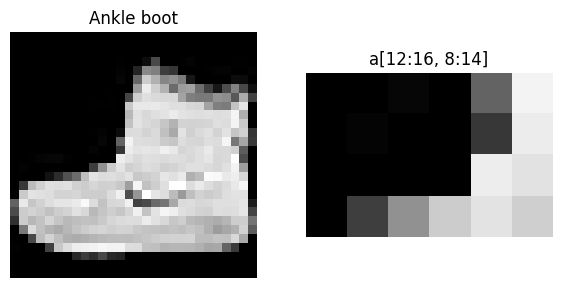

[[  0   0   6   0  99 244]
 [  0   4   0   0  55 236]
 [  0   0   0   0 237 226]
 [  0  62 145 204 228 207]]


In [5]:
# ▶ 그대로 실행하세요 — 사진과 가운데 4×6칸의 숫자
fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
axes[0].imshow(a, cmap='gray')
axes[0].set_title(fmnist.classes[label])
axes[1].imshow(a[12:16, 8:14], cmap='gray', vmin=0, vmax=255)
axes[1].set_title('a[12:16, 8:14]')
for ax in axes:
    ax.axis('off')
plt.show()
print(a[12:16, 8:14])

💬 오른쪽 그림의 밝은 칸이 200대, 검은 칸이 0입니다. 숫자와 밝기가 일대일로 대응합니다.

---

## 2. 컬러 사진은 채널 축이 하나 더 있다

CIFAR-10은 32×32 컬러 사진입니다. 한 장을 배열로 만들면 축이 하나 더 있습니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
img_c, label_c = cifar[0]
arr = np.array(img_c)

print(cifar.classes[label_c])
print(arr.shape, arr.dtype)
print(arr[:, :, 0].shape)
```

In [10]:
img_c, label_c = cifar[0]
arr = np.array(img_c) # 이미지를 numpy array로 변환

print(cifar.classes[label_c])
print(arr.shape, arr.dtype)
print(arr[:,:,0].shape) # 첫 번째 채널에 채널의 데이터 크기

frog
(32, 32, 3) uint8
(32, 32)


✅ **체크포인트** — `frog`, `(32, 32, 3) uint8`, `(32, 32)`면 맞습니다.

💬 **결과 해설** — 마지막 축 3이 **R, G, B 채널**입니다. `arr[:, :, 0]`은 빨강 채널 한 장이고 흑백 사진과 같은 `(32, 32)`입니다. 컬러 사진 한 장은 같은 크기의 흑백 행렬 세 장을 겹친 것입니다.

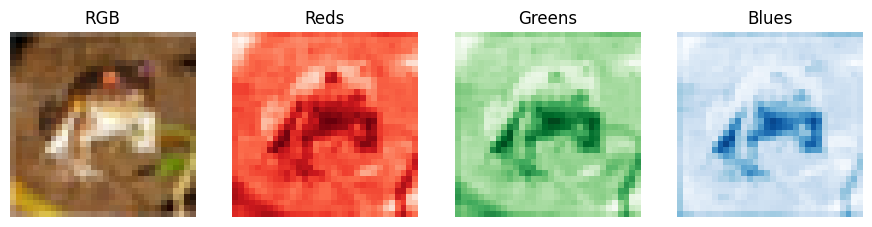

In [12]:
# ▶ 그대로 실행하세요 — 원본과 채널 세 장
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
axes[0].imshow(arr)
axes[0].set_title('RGB')
for i, name in enumerate(['Reds', 'Greens', 'Blues']):
    axes[i + 1].imshow(arr[:, :, i], cmap=name, vmin=0, vmax=255)
    axes[i + 1].set_title(name)
for ax in axes:
    ax.axis('off')
plt.show()

---

## 3. 신경망에 넣기 전 변환

PIL과 matplotlib은 `(높이, 너비, 채널)`로 다루지만, PyTorch는 **채널을 앞에** 두는 `(채널, 높이, 너비)`를 씁니다. `transforms.ToTensor()`는 PIL 이미지를 텐서로 바꾸면서 두 가지를 한꺼번에 합니다. 축을 `(C, H, W)`로 옮기고, 값을 255로 나누어 **0~1 사이의 실수**로 만듭니다. 픽셀의 최솟값 0과 최댓값 255는 어떤 사진이든 같으므로, 255로 나누는 것이 곧 **min-max 스케일링**입니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
to_tensor = transforms.ToTensor()
x = to_tensor(img_c)

print(tuple(x.shape), x.dtype)
print(x.min().item(), x.max().item())
print(arr[0, 0], x[:, 0, 0])
```

In [13]:
to_tensor = transforms.ToTensor()
x = to_tensor(img_c)

print(tuple(x.shape), x.dtype) # 채널x가로x세로
print(x.min().item(), x.max().item()) # 스케일링
print(arr[0, 0], x[:, 0, 0])

(3, 32, 32) torch.float32
0.0 1.0
[59 62 63] tensor([0.2314, 0.2431, 0.2471])


✅ **체크포인트** — `(3, 32, 32) torch.float32`, `0.0 1.0`이면 맞습니다.

💬 **결과 해설** — 마지막 줄이 왼쪽 위 픽셀 하나입니다. 배열에서는 `[59 62 63]`이던 R, G, B가 텐서에서는 `0.2314, 0.2431, 0.2471`입니다. 59/255 = 0.2314로, 같은 픽셀이 축 순서와 눈금만 바뀌어 들어 있습니다.

`ToTensor()`를 데이터셋에 `transform`으로 넘기면 사진을 꺼낼 때마다 자동으로 적용됩니다. 실습 4의 `DataLoader`를 그대로 써서 64장을 꺼냅니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
cifar_t = datasets.CIFAR10(root='./data', train=True, download=False, transform=transforms.ToTensor())
loader = DataLoader(cifar_t, batch_size=64, shuffle=True)

xb, yb = next(iter(loader))
print(tuple(xb.shape), tuple(yb.shape))
```

In [14]:
cifar_t = datasets.CIFAR10(root='./data', train=True, download=False, transform=transforms.ToTensor())
loader = DataLoader(cifar_t, batch_size=64, shuffle=True)

xb, yb = next(iter(loader)) # 배치데이터를 순서대로 불러오는 부부
print(tuple(xb.shape), tuple(yb.shape))

(64, 3, 32, 32) (64,)


✅ **체크포인트** — `(64, 3, 32, 32) (64,)`이면 맞습니다.

💬 **결과 해설** — 앞으로 나오는 모든 이미지 텐서는 이 네 축 **`(N, C, H, W)`**를 갖습니다. N은 배치 크기, C는 채널, H와 W는 높이와 너비입니다. 실습 4의 `(32, 9)`에서 N은 그대로이고, 변수 축 하나가 `(C, H, W)` 세 축으로 바뀌었습니다.

---

## 4. 펼쳐서 넣으면 파라미터가 폭발한다

이론 5장의 방식대로 사진 한 장을 한 줄로 펼쳐 `nn.Linear`에 넣어 봅니다. `flatten(start_dim=1)`은 N축은 두고 나머지를 한 줄로 잇습니다. 은닉 노드는 5장과 같이 256개이고, 파라미터 수는 실습 2의 규칙 $n_{\text{in}} \times n_{\text{out}} + n_{\text{out}}$입니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
flat = xb.flatten(start_dim=1)
fc = nn.Linear(3 * 32 * 32, 256)

print(tuple(flat.shape))
print(fc.weight.shape, fc.bias.shape)
print(3 * 32 * 32 * 256 + 256)
```

In [15]:
flat = xb.flatten(start_dim=1)
fc = nn.Linear(3 * 32 * 32, 256)

print(tuple(flat.shape))
print(fc.weight.shape, fc.bias.shape)
print(3 * 32 * 32 * 256 + 256)

(64, 3072)
torch.Size([256, 3072]) torch.Size([256])
786688


✅ **체크포인트** — 펼친 길이 `3072`, 가중치 `(256, 3072)`, 파라미터 **786,688**개면 맞습니다.

💬 **결과 해설** — 32×32짜리 작은 사진을 층 하나에 넣는 데 79만 개입니다. 5장의 224×224 사진이면 몇 개가 되는지는 과제 2에서 셉니다. 이것이 **파라미터 폭발**이고, 5절의 콘볼루션이 푸는 문제입니다.

---

## 5. 콘볼루션을 코드로 계산한다

이론 6장에서 손으로 계산한 2채널 예제를 그대로 가져옵니다. 채널 2개의 3×3 입력과 채널 2개의 2×2 커널이고, 6장과 같이 편향은 0입니다. 계산 원리는 6장에서 봤으므로 여기서는 PyTorch로 결과만 냅니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
x2 = torch.tensor([[[1, 2, 0], [0, 1, 3], [2, 1, 1]],
                   [[0, 1, 1], [2, 0, 1], [1, 2, 0]]], dtype=torch.float32)
k2 = torch.tensor([[[1, 0], [0, 1]],
                   [[0, 1], [1, 0]]], dtype=torch.float32)

print(x2.shape, k2.shape)
```

In [17]:
x2 = torch.tensor([[[1, 2, 0], [0, 1, 3], [2, 1, 1]],
                   [[0, 1, 1], [2, 0, 1], [1, 2, 0]]], dtype=torch.float32)
k2 = torch.tensor([[[1, 0], [0, 1]],
                   [[0, 1], [1, 0]]], dtype=torch.float32)

print(x2.shape, k2.shape)

torch.Size([2, 3, 3]) torch.Size([2, 2, 2])


💬 **결과 해설** — 입력은 `(2, 3, 3)`, 커널은 `(2, 2, 2)`입니다. 첫 축이 채널이고, 커널의 채널 수는 입력의 채널 수와 같습니다.

PyTorch의 콘볼루션 `F.conv2d`는 배치 단위로 계산하므로 입력은 `(N, C, H, W)`, 커널은 `(커널 수, 입력 채널 수, KH, KW)`여야 합니다. `unsqueeze(0)`은 맨 앞에 길이 1인 축을 하나 더합니다. 사진 한 장을 배치 하나로, 커널 한 개를 커널 묶음으로 만드는 것입니다.


**✍️ 직접 입력** — 아래 코드를 보고 **직접 타이핑**해서 실행하세요. (복사·붙여넣기 말고 손으로)

```python
xt = x2.unsqueeze(0)
kt = k2.unsqueeze(0)

y = F.conv2d(xt, kt)
print(tuple(xt.shape), tuple(kt.shape), '->', tuple(y.shape))
print(y[0, 0])
```

In [18]:
xt = x2.unsqueeze(0)
kt = k2.unsqueeze(0)

y = F.conv2d(xt, kt)
print(tuple(xt.shape), tuple(kt.shape), '->', tuple(y.shape))
print(y[0, 0])

(1, 2, 3, 3) (1, 2, 2, 2) -> (1, 1, 2, 2)
tensor([[5., 6.],
        [2., 5.]])


✅ **체크포인트** — `(1, 2, 3, 3) (1, 2, 2, 2) -> (1, 1, 2, 2)`이고 값이 `[[5, 6], [2, 5]]`면 맞습니다. 6장 보드의 마지막 스텝과 같은 값입니다.

💬 **결과 해설** — 채널별 결과는 따로 쌓이지 않고 더해져서 특성 맵 **한 장**이 됩니다.
- 커널의 두 번째 축은 **입력 채널 수와 같아야** 합니다. 콘볼루션에서 나는 모양 오류의 대부분이 이 축입니다.
- 커널의 첫 축이 커널의 개수이고 그대로 출력 채널 수가 됩니다. 커널이 8개면 특성 맵도 8장입니다. 5-2에서 그렇게 씁니다.

---

## 6. 실습 과제 (10분)

### 📝 과제 1 · 텐서를 그림으로 보기

3절의 `x`는 `(3, 32, 32)`입니다. `plt.imshow`는 `(높이, 너비, 채널)`만 받으므로 축을 되돌려야 그릴 수 있습니다. `permute`로 축 순서를 바꿔 모양을 확인하고 그립니다.

In [ ]:
# 📝 과제 — 여기에 코드를 작성하세요
# 힌트: x.permute(1, 2, 0)은 "원래 1번 축을 0번으로, 2번을 1번으로, 0번을 2번으로" 옮깁니다. 모양을 tuple(...shape)로 출력한 뒤 plt.imshow에 넣습니다.


✏️ **나의 답:** 되돌린 모양 `(___, ___, ___)`


### 📝 과제 2 · 224×224 사진이면 파라미터는 몇 개인가

이론 5장의 224×224 컬러 사진을 같은 은닉 노드 256개에 연결할 때의 파라미터 수를 먼저 손으로 계산한 뒤 코드로 확인합니다.

In [ ]:
# 📝 과제 — 여기에 코드를 작성하세요
# 힌트: 4절 셀에서 32를 224로 바꿉니다. nn.Linear(3 * 224 * 224, 256)의 weight.shape와 공식 3*224*224*256 + 256을 함께 출력합니다.

| 입력 크기 | 펼친 길이 | 파라미터 수 |
|---|---|---|
| 32×32×3 | 3,072 | 786,688 |
| 224×224×3 | ✏️ | ✏️ |


### 📝 과제 3 · 세로 에지 커널

왼쪽 두 열이 10, 나머지가 0인 5×5 흑백 이미지에 이론 6장의 세로 에지 커널 `[[1, 0, -1], [1, 0, -1], [1, 0, -1]]`을 `F.conv2d`로 적용합니다. 출력 크기와 값이 큰 위치를 먼저 예상합니다.

In [20]:
# 📝 과제 — 여기에 코드를 작성하세요
# 힌트: 이미지는 torch.zeros(1, 5, 5)를 만든 뒤 img_e[0, :, :2] = 10으로 왼쪽 두 열을 채웁니다. 커널은 5절의 k2처럼 (1, 3, 3) 모양의 torch.tensor입니다. 둘 다 unsqueeze(0)으로 축을 하나 더해 F.conv2d에 넣고, 결과의 [0, 0]을 출력합니다.
img_e = torch.zeros(1,5,5)
img_e[0,:,:2] = 10
edge_kernel = torch.tensor([[[1,0,-1],
                             [1,0,-1],
                            [1,0,-1]]], dtype = torch.float32)
xt = img_e.unsqueeze(0)
kt = edge_kernel.unsqueeze(0)
y = F.conv2d(xt,kt)
print(y[0,0])

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


✏️ **나의 답:** 출력 크기 ___, 값이 큰 열 ___


### 📝 과제 4 · 생각해 보기

실습 4에서는 표준화의 평균과 표준편차를 **훈련 세트에서** 구했습니다. `ToTensor`가 255로 나눌 때는 왜 훈련 세트에서 값을 구하지 않아도 될까요? 한두 문장으로 적습니다.

✏️ **나의 답:**


---

## ✅ 정리

| 배운 것 | 핵심 |
|---|---|
| 흑백 한 장 | `np.array(img)` → `(28, 28)` uint8, 0~255. 칸 하나가 픽셀 |
| 컬러 한 장 | `(32, 32, 3)`. 마지막 축이 R, G, B. `arr[:, :, 0]`이 빨강 채널 |
| 변환 | `ToTensor`: `(H, W, C)` → `(C, H, W)`, ÷255로 0~1(min-max). 데이터셋에 `transform=`으로 넘김 |
| 배치 | `DataLoader`에서 `(N, C, H, W)`. `(64, 3, 32, 32)` |
| 파라미터 폭발 | 펼치면 3,072 → Linear(→256) 786,688개. 224×224면 38,535,424개 |
| `F.conv2d` | 입력 `(N, C, H, W)`, 커널 `(커널 수, C, KH, KW)`. `unsqueeze(0)`으로 축을 더함. 6장 예제 `[[5, 6], [2, 5]]` |

**다음:** [실습 5-2](https://ralbu85.github.io/lecture_deeplearning/labs/lab05_2.html)에서 출력 크기 공식과 파라미터 수를 검산하고, 콘볼루션 층 하나로 옷 사진 열 종류를 분류합니다.